# 1 · Simulating a UPI platform

No public dataset has user-level UPI behaviour, so we **simulate** one: 100,000 users over 18 months.

The point of simulating is that we **know the truth**. We plant specific behaviours, then check whether the
SQL and statistics in notebooks 2 and 3 rediscover them from the raw tables alone. If an analysis can't find an
effect we know is there, the analysis is wrong.

| Planted behaviour | Mechanism |
|---|---|
| Platform grows, with campaign spikes in Jun & Dec 2024 | signup weights rise linearly, x1.6 in campaign months |
| Referral users are more engaged; paid users less | hidden engagement multiplier 1.3 / 1.0 / 0.8 |
| Tier-1 cities more engaged; tier-3 completes KYC less | engagement x1.2 / 1.0 / 0.85; KYC -6pp in tier 3 |
| **Merchant payment in week 1 → much lower churn** | monthly churn hazard x0.55 if activated |
| Churn risk falls with tenure | hazard = 0.40 x 0.88^k |
| 3 A/B tests with known effects | cashback +0.35 logit; KYC flow +2.5pp; banner = 0 (null) |

The engagement score is **never saved** — like real data, we only see behaviour.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from upi import config, db, plots

In [2]:
from upi.simulate import simulate
from upi.config import SimConfig
cfg = SimConfig()
cfg

SimConfig(n_users=100000, n_months=18, start_date='2024-01-01', seed=42, campaign_months=(5, 11), campaign_boost=1.6, base_kyc_rate=0.85, tier3_kyc_penalty=0.06, activation_intercept=-0.8, activation_engagement_coef=1.0, base_churn=0.4, churn_decay=0.88, activated_churn_mult=0.55, referral_churn_mult=0.8, monthly_txn_rate=3.0, activated_rate_mult=1.5, failure_rate=0.02, merchant_revenue_rate=0.003, bill_pay_fee=2.0, recharge_fee=1.5, referral_banner_effect=0.0, cashback_logit_lift=0.35, kyc_flow_lift=0.025)

## The tables

Run `make simulate` (or `python -m upi.cli simulate`) to (re)generate. Here we read the saved output.

In [3]:
users = pd.read_parquet(config.SIM_DIR / "users.parquet")
tx = pd.read_parquet(config.SIM_DIR / "transactions.parquet")
exp = pd.read_parquet(config.SIM_DIR / "experiments.parquet")
print(f"users {len(users):,} | transactions {len(tx):,} | experiment participants {len(exp):,}")
users.head()

users 100,000 | transactions 1,335,792 | experiment participants 63,089


,user_id,signup_date,channel,city_tier,age_group,device,kyc_completed_at
0,1,2024-01-01,paid,1,45+,android,2024-01-02
1,2,2024-01-01,paid,3,18-24,android,2024-01-02
2,3,2024-01-01,referral,2,18-24,android,2024-01-02
3,4,2024-01-01,referral,3,25-34,android,2024-01-03
4,5,2024-01-01,referral,2,45+,android,2024-01-01


In [4]:
tx.head()

,txn_id,user_id,txn_date,category,amount,status,revenue
0,1,5,2024-01-01,merchant,98.59,success,0.30
1,2,55,2024-01-01,merchant,53.54,success,0.16
2,3,94,2024-01-01,p2p,530.92,success,0.00
3,4,17,2024-01-02,bill_pay,108.51,success,2.00
4,5,17,2024-01-02,bill_pay,664.29,success,2.00


In [5]:
exp.groupby(['experiment_name', 'variant']).size().unstack()

variant,control,treatment
experiment_name,,
first_merchant_cashback,9965,10021
referral_nudge_banner,10228,10338
simplified_kyc_flow,11238,11299


## Sanity checks on the generated data

In [6]:
print("Category mix:"); print(tx["category"].value_counts(normalize=True).round(3))
print("\nMedian amount by category (Rs):"); print(tx.groupby("category")["amount"].median().round(0))
print(f"\nFailed transactions: {(tx['status'] == 'failed').mean():.1%}")
print(f"KYC completion: {users['kyc_completed_at'].notna().mean():.1%}")

Category mix:
category
p2p         0.411
merchant    0.316
bill_pay    0.171
recharge    0.102
Name: proportion, dtype: float64

Median amount by category (Rs):
category
bill_pay    899.0
merchant    200.0
p2p         492.0
recharge    245.0
Name: amount, dtype: float64

Failed transactions: 2.0%
KYC completion: 83.6%


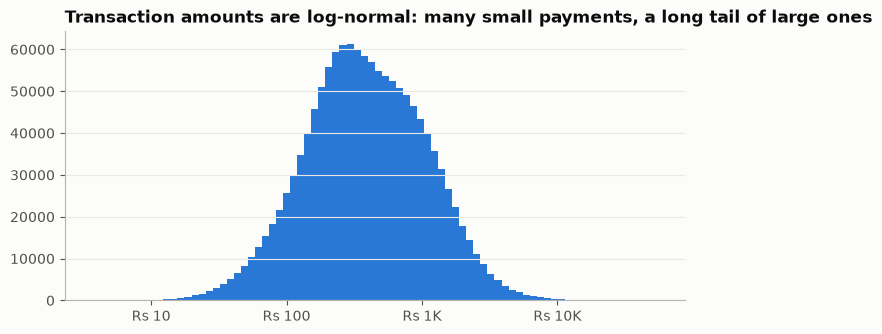

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(tx["amount"]), bins=80, color=plots.SERIES[0])
ax.set_xticks([1, 2, 3, 4], ["Rs 10", "Rs 100", "Rs 1K", "Rs 10K"])
ax.set_title("Transaction amounts are log-normal: many small payments, a long tail of large ones")
plt.show()

## Ground truth (used only for validation, never by the analysis)

In [8]:
import json
truth = json.loads((config.SIM_DIR / "ground_truth.json").read_text())
pd.DataFrame({k: {**v["true_kyc_rate"], **{f"activation_{a}": b for a, b in v["true_activation_rate"].items()}}
              for k, v in truth["experiments"].items()}).T.round(4)

,control,treatment,activation_control,activation_treatment
referral_nudge_banner,0.8353,0.8352,0.2748,0.2737
first_merchant_cashback,0.8353,0.8347,0.2746,0.3374
simplified_kyc_flow,0.8349,0.8602,0.2727,0.2820
